# Exercise 3: Regularisation and Generalisation of the CNN on CIFAR-10
PUSL3123 AI and Machine Learning, Assessment 1

**Aim:** Using the CNN from Exercise 2 as the baseline, investigate how dropout and data augmentation affect generalisation. Each technique is first evaluated independently against the unchanged baseline, and then the two are combined.

**Dependencies:** Python 3, PyTorch, torchvision, numpy, matplotlib. Run all cells from top to bottom (the four training runs take roughly 25-30 minutes on a Colab T4 GPU; the augmentation runs are slower because image transformations run on the CPU).

## 1. Data preparation and setup
- CIFAR-10: 50,000 training and 10,000 test images (32x32 RGB, 10 classes).
- The training images are split into 45,000 train and 5,000 validation images with a fixed seed (42), identical to Exercises 1 and 2. The test set is kept separate.
- Images are normalised per channel with the CIFAR-10 mean and standard deviation. Batch size is 128.

In [1]:
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np, random


SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
base_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

full_train = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=base_tf)
test_set   = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=base_tf)
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]

train_loader = DataLoader(Subset(full_train, train_idx), batch_size=128, shuffle=True, num_workers=2)
val_loader   = DataLoader(Subset(full_train, val_idx),   batch_size=128, num_workers=2)
test_loader  = DataLoader(test_set, batch_size=128, num_workers=2)


def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=20, lr=1e-3):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(h, (tl, vl, ta, va)): h[k].append(v)
        print(f"Epoch {ep+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    return h

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def plot_history(h, title):
    epochs = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epochs, h["train_loss"], label="train"); ax[0].plot(epochs, h["val_loss"], label="validation")
    ax[0].set(title=f"{title}: loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
    ax[1].plot(epochs, h["train_acc"], label="train"); ax[1].plot(epochs, h["val_acc"], label="validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
    plt.show()


print("Train / val / test sizes:", len(train_idx), len(val_idx), len(test_set))

Device: cpu


100%|██████████| 170M/170M [00:47<00:00, 3.56MB/s]


Train / val / test sizes: 45000 5000 10000


## 2. Models and regularisation techniques

**Baseline CNN (unchanged from Exercise 2):** two convolutional layers (32 and 64 filters, 3x3, padding 1, ReLU, 2x2 max-pooling) followed by one linear layer (4096 -> 10). It has three trainable layers and 60,362 trainable parameters.

**Dropout:** a dropout layer with probability 0.5 is inserted after the flatten operation, immediately before the final linear layer. This layer contains 40,970 of the 60,362 parameters (about 68%), so it is the part of the network most able to memorise the training data. Dropout adds no trainable parameters.

**Data augmentation:** the training images are randomly transformed each time they are loaded: rotation of up to 10 degrees, translation of up to 10% of the image size in each direction, and horizontal flips. Augmentation is applied to the training images only. The validation and test images are never augmented.



In [2]:
def build_cnn(dropout=0.0):
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Dropout(dropout) if dropout > 0 else nn.Identity(),
        nn.Linear(64 * 8 * 8, 10))

# Augmentation: training images only. Validation and test stay clean.
aug_tf = T.Compose([T.RandomRotation(10),
                    T.RandomAffine(degrees=0, translate=(0.1, 0.1)),
                    T.RandomHorizontalFlip(),
                    T.ToTensor(), T.Normalize(MEAN, STD)])
aug_full = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=aug_tf)
train_loader_aug = DataLoader(Subset(aug_full, train_idx), batch_size=128, shuffle=True, num_workers=2)

def run_experiment(name, dropout=0.0, augment=False, seed=SEED, epochs=20):
    torch.manual_seed(seed)
    model = build_cnn(dropout)
    h = fit(model, train_loader_aug if augment else train_loader, val_loader, epochs=epochs)
    crit = nn.CrossEntropyLoss()
    r = {"name": name, "params": count_params(model), "history": h}
    # final metrics: eval mode, CLEAN data (train_loader is not augmented)
    for split, ld in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
        r[split + "_loss"], r[split + "_acc"] = run_epoch(model, ld, crit)
    r["gap"] = r["train_acc"] - r["test_acc"]
    return r

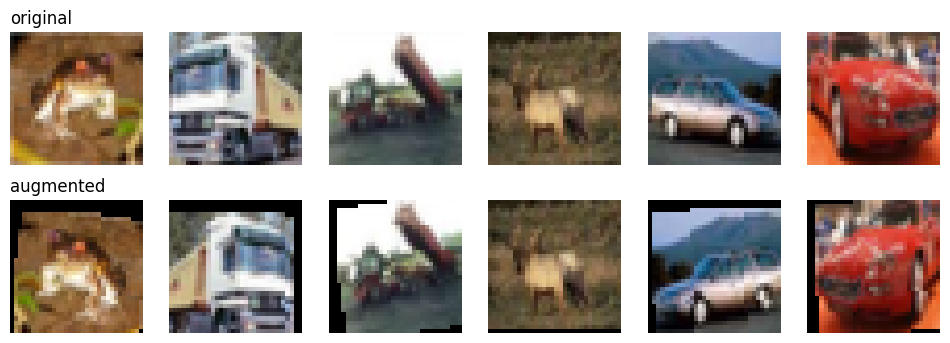

In [3]:
raw = torchvision.datasets.CIFAR10("./data", train=True, download=False)
look = T.Compose([T.RandomRotation(10), T.RandomAffine(0, translate=(0.1, 0.1)), T.RandomHorizontalFlip()])
fig, ax = plt.subplots(2, 6, figsize=(12, 4))
for i in range(6):
    img, _ = raw[i]
    ax[0, i].imshow(img); ax[0, i].axis("off")
    ax[1, i].imshow(look(img)); ax[1, i].axis("off")
ax[0, 0].set_title("original", loc="left"); ax[1, 0].set_title("augmented", loc="left")
plt.show()

*Figure 1: original CIFAR-10 images (top) and augmented versions (bottom).*

## 3. Experimental design
Four models are trained under identical conditions: the same data split, seed (42), Adam optimiser (learning rate 0.001), batch size 128, cross-entropy loss and 20 epochs. Only the regularisation changes:

1. Baseline (no regularisation)
2. Dropout (p = 0.5)
3. Data augmentation
4. Dropout + data augmentation

The regularisation settings (p = 0.5, rotation 10 degrees, translation 10%) were fixed in advance and were not tuned using the test set. After training, each model is evaluated once on the clean training set (without augmentation), the validation set and the test set, in evaluation mode (dropout off). Training accuracy is measured this way so that the training/test comparison is fair. The baseline was retrained in this notebook through the same pipeline as the other runs, so its numbers differ slightly from Exercise 2 because of run-to-run GPU variation.

In [4]:
results = {}
results["Baseline"] = run_experiment("Baseline")

Epoch  1 | train loss 1.390 acc 0.508 | val loss 1.112 acc 0.615
Epoch  2 | train loss 1.025 acc 0.645 | val loss 0.983 acc 0.657
Epoch  3 | train loss 0.897 acc 0.691 | val loss 0.932 acc 0.676
Epoch  4 | train loss 0.806 acc 0.724 | val loss 0.912 acc 0.687
Epoch  5 | train loss 0.741 acc 0.747 | val loss 0.864 acc 0.710
Epoch  6 | train loss 0.686 acc 0.765 | val loss 0.877 acc 0.698
Epoch  7 | train loss 0.641 acc 0.780 | val loss 0.890 acc 0.701
Epoch  8 | train loss 0.602 acc 0.793 | val loss 0.854 acc 0.716
Epoch  9 | train loss 0.561 acc 0.808 | val loss 0.855 acc 0.716
Epoch 10 | train loss 0.528 acc 0.819 | val loss 0.864 acc 0.718
Epoch 11 | train loss 0.498 acc 0.827 | val loss 0.897 acc 0.710
Epoch 12 | train loss 0.470 acc 0.838 | val loss 0.902 acc 0.717
Epoch 13 | train loss 0.444 acc 0.846 | val loss 0.934 acc 0.714
Epoch 14 | train loss 0.420 acc 0.857 | val loss 0.939 acc 0.713
Epoch 15 | train loss 0.394 acc 0.863 | val loss 0.981 acc 0.713
Epoch 16 | train loss 0.3

In [5]:
results["Dropout"] = run_experiment("Dropout (p=0.5)", dropout=0.5)

Epoch  1 | train loss 1.478 acc 0.473 | val loss 1.195 acc 0.585
Epoch  2 | train loss 1.165 acc 0.590 | val loss 1.034 acc 0.641
Epoch  3 | train loss 1.043 acc 0.635 | val loss 0.950 acc 0.674
Epoch  4 | train loss 0.975 acc 0.661 | val loss 0.909 acc 0.693
Epoch  5 | train loss 0.920 acc 0.681 | val loss 0.883 acc 0.698
Epoch  6 | train loss 0.886 acc 0.692 | val loss 0.854 acc 0.705
Epoch  7 | train loss 0.858 acc 0.701 | val loss 0.813 acc 0.717
Epoch  8 | train loss 0.830 acc 0.710 | val loss 0.831 acc 0.722
Epoch  9 | train loss 0.816 acc 0.716 | val loss 0.816 acc 0.714
Epoch 10 | train loss 0.793 acc 0.725 | val loss 0.789 acc 0.730
Epoch 11 | train loss 0.779 acc 0.729 | val loss 0.794 acc 0.733
Epoch 12 | train loss 0.762 acc 0.737 | val loss 0.777 acc 0.734
Epoch 13 | train loss 0.749 acc 0.741 | val loss 0.770 acc 0.729
Epoch 14 | train loss 0.733 acc 0.745 | val loss 0.766 acc 0.739
Epoch 15 | train loss 0.724 acc 0.747 | val loss 0.757 acc 0.744
Epoch 16 | train loss 0.7

In [6]:
results["Augmentation"] = run_experiment("Augmentation", augment=True)

Epoch  1 | train loss 1.572 acc 0.436 | val loss 1.265 acc 0.555
Epoch  2 | train loss 1.260 acc 0.555 | val loss 1.095 acc 0.617
Epoch  3 | train loss 1.141 acc 0.599 | val loss 1.060 acc 0.632
Epoch  4 | train loss 1.066 acc 0.627 | val loss 1.002 acc 0.653
Epoch  5 | train loss 1.024 acc 0.644 | val loss 0.925 acc 0.676
Epoch  6 | train loss 0.986 acc 0.657 | val loss 0.885 acc 0.690
Epoch  7 | train loss 0.961 acc 0.666 | val loss 0.881 acc 0.694
Epoch  8 | train loss 0.935 acc 0.675 | val loss 0.837 acc 0.714
Epoch  9 | train loss 0.913 acc 0.683 | val loss 0.854 acc 0.701
Epoch 10 | train loss 0.903 acc 0.687 | val loss 0.805 acc 0.718
Epoch 11 | train loss 0.886 acc 0.692 | val loss 0.822 acc 0.714
Epoch 12 | train loss 0.870 acc 0.698 | val loss 0.795 acc 0.728
Epoch 13 | train loss 0.858 acc 0.702 | val loss 0.800 acc 0.724
Epoch 14 | train loss 0.848 acc 0.706 | val loss 0.764 acc 0.733
Epoch 15 | train loss 0.838 acc 0.708 | val loss 0.770 acc 0.734
Epoch 16 | train loss 0.8

In [7]:
results["Both"] = run_experiment("Dropout + Augmentation", dropout=0.5, augment=True)

Epoch  1 | train loss 1.641 acc 0.409 | val loss 1.325 acc 0.526
Epoch  2 | train loss 1.364 acc 0.511 | val loss 1.146 acc 0.604
Epoch  3 | train loss 1.262 acc 0.551 | val loss 1.055 acc 0.637
Epoch  4 | train loss 1.195 acc 0.577 | val loss 1.028 acc 0.653
Epoch  5 | train loss 1.155 acc 0.594 | val loss 0.976 acc 0.658
Epoch  6 | train loss 1.120 acc 0.607 | val loss 0.946 acc 0.668
Epoch  7 | train loss 1.089 acc 0.615 | val loss 0.901 acc 0.690
Epoch  8 | train loss 1.066 acc 0.625 | val loss 0.899 acc 0.687
Epoch  9 | train loss 1.050 acc 0.633 | val loss 0.887 acc 0.688
Epoch 10 | train loss 1.032 acc 0.640 | val loss 0.853 acc 0.706
Epoch 11 | train loss 1.011 acc 0.647 | val loss 0.858 acc 0.696
Epoch 12 | train loss 1.006 acc 0.648 | val loss 0.828 acc 0.709
Epoch 13 | train loss 0.992 acc 0.652 | val loss 0.836 acc 0.711
Epoch 14 | train loss 0.985 acc 0.655 | val loss 0.806 acc 0.725
Epoch 15 | train loss 0.974 acc 0.658 | val loss 0.807 acc 0.724
Epoch 16 | train loss 0.9

In [8]:
print(f"{'Model':<24}{'Params':>8}{'Train acc':>11}{'Test acc':>10}{'Gap':>8}{'Val loss':>10}")
for r in results.values():
    print(f"{r['name']:<24}{r['params']:>8,}{r['train_acc']:>11.3f}{r['test_acc']:>10.3f}{r['gap']:>8.3f}{r['val_loss']:>10.3f}")

Model                     Params  Train acc  Test acc     Gap  Val loss
Baseline                  60,362      0.922     0.704   0.218     1.118
Dropout (p=0.5)           60,362      0.833     0.750   0.083     0.733
Augmentation              60,362      0.777     0.747   0.030     0.729
Dropout + Augmentation    60,362      0.750     0.733   0.017     0.770


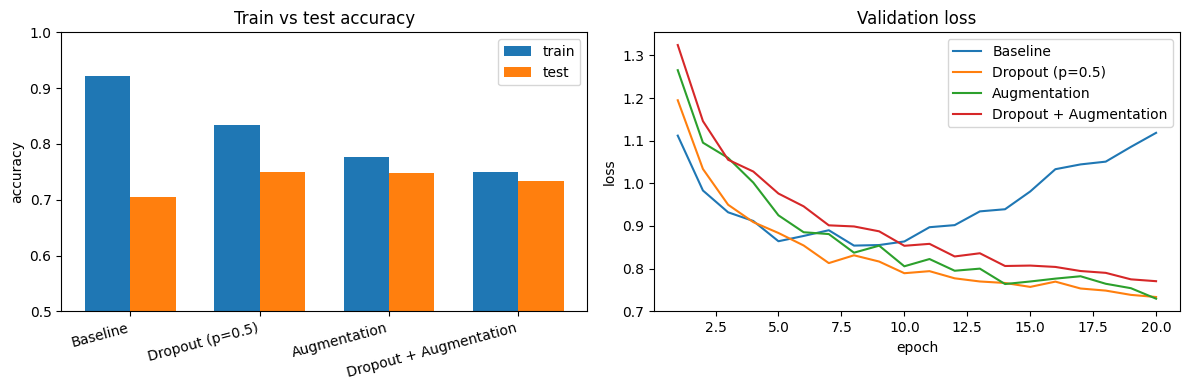

In [9]:
names = [r["name"] for r in results.values()]
x, w = np.arange(len(names)), 0.35
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(x - w/2, [r["train_acc"] for r in results.values()], w, label="train")
ax[0].bar(x + w/2, [r["test_acc"] for r in results.values()], w, label="test")
ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=15)
ax[0].set(ylim=(0.5, 1.0), ylabel="accuracy", title="Train vs test accuracy"); ax[0].legend()
for r in results.values():
    ax[1].plot(range(1, 21), r["history"]["val_loss"], label=r["name"])
ax[1].set(title="Validation loss", xlabel="epoch", ylabel="loss"); ax[1].legend()
ax[0].set_xticklabels(names, rotation=15, ha="right")
plt.tight_layout()

plt.show()

## 4. Results

| Model | Trainable params | Train acc | Test acc | Gap (points) | Final val loss |
|---|---|---|---|---|---|
| Baseline | 60,362 | 92.2% | 70.4% | 21.8 | 1.118 |
| Dropout (p = 0.5) | 60,362 | 83.3% | 75.0% | 8.3 | 0.733 |
| Augmentation | 60,362 | 77.7% | 74.7% | 3.0 | 0.729 |
| Dropout + Augmentation | 60,362 | 75.0% | 73.3% | 1.7 | 0.770 |

Gap = training accuracy minus test accuracy. Training accuracy was measured on clean (un-augmented) training images in evaluation mode.

| Model | Lowest validation loss | Epoch | Final (epoch 20) |
|---|---|---|---|
| Baseline | 0.854 | 8 | 1.118 |
| Dropout (p = 0.5) | 0.733 | 20 | 0.733 |
| Augmentation | 0.729 | 20 | 0.729 |
| Dropout + Augmentation | 0.770 | 20 | 0.770 |

*Figure 2: (left) training vs test accuracy for each model (y-axis starts at 0.5); (right) validation loss over 20 epochs.*

In [10]:
for r in results.values():
    v = r["history"]["val_loss"]
    b = min(range(len(v)), key=lambda i: v[i])
    print(f"{r['name']:<24} best val loss {v[b]:.3f} at epoch {b+1} | final {v[-1]:.3f}")

Baseline                 best val loss 0.854 at epoch 8 | final 1.118
Dropout (p=0.5)          best val loss 0.733 at epoch 20 | final 0.733
Augmentation             best val loss 0.729 at epoch 20 | final 0.729
Dropout + Augmentation   best val loss 0.770 at epoch 20 | final 0.770


In [11]:
import json
json.dump(results, open("ex3_main.json", "w"))

An earlier run of the same experiments gave very similar results and the same ordering of models (test accuracy 70.0%, 75.2%, 74.7% and 73.2%).

## 5. Discussion

The baseline CNN definitely overfits. It's training accuracy is 92.2%, which is 21.8 points higher than its test accuracy of 70.4% and its validation loss is as low as 0.854 at epoch 8 and climbs higher while the training loss keeps decreasing.

Generalisation was significantly enhanced by both regularisation methods. Dropout improved the accuracy on the test set by 4.6 points to 75.0%, and narrowed the gap between training and test loss by 8.3 points to 21.8, with the validation loss continuing to decrease during training. A probable explanation is that the most recent linear layer has approximately 68% of the network parameters, which means it is the layer where most memorization may happen. The net is made to distribute the evidence over many of its inputs instead of just a few by randomly pruning half of them while it is being trained.By randomly pruning half of the inputs while training the net, it is made to distribute the evidence over many of its inputs, rather than a few, which is similar to averaging over many smaller nets.

The data augmentation technique yielded a test improvement of +4.3 points (87.7%) and the smallest gap between any single techniques (3.0 points). The network has no idea that the same image will appear again for this reason; it is not possible for it to memorise each image and it is encouraged to look for features that are similar even if the image is slightly rotated, shifted or flipped, which are realistic variations in the position or orientation of the image. Its training accuracy (77.7%) is significantly lower as is expected if the training task is made more difficult. The difference of 0.3 points between dropout and augmentation is not enough to indicate that augmentation is better than dropout or vice versa.

The addition of the two didn't provide much extra value. It resulted in a minimal gap (1.7 points), but the test accuracy (73.3%) was less than either of the two alone and the validation loss (0.770) was greater. The training accuracy is 75.0%, which is near the test accuracy, indicating that the limited training length and capacity (underfitting) were the factors that limit the model performance with both regularisers, not overfitting. This corresponds to the smallest validation loss at epoch 20, which it had as well as the other three regularised models, and with an extended training period could be improved – this was not done here. A small gap therefore just means the test performance matches the training performance and it does not necessarily mean it is the best model.

Despite the fact that these conclusions are based on a single training run with a single seed, differences of a point or less should not be over-interpreted. The substantial effects (the roughly 3-5 point gains over the baseline and the large reduction in the gap) are much larger than that, but the ranking between dropout and augmentation is uncertain.